In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [ ]:
roll_number = "P26CS0006"
seed = int(''.join(c for c in roll_number if c.isdigit()))

faces = fetch_olivetti_faces()

X = faces.data
y = faces.target

print("Seed:", seed)
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Classes:", len(np.unique(y)))

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Seed: 260006
X shape: (400, 4096)
y shape: (400,)
Classes: 40


In [ ]:
rng = np.random.default_rng(seed)

train_idx = []
val_idx = []
test_idx = []

for person in range(40):

    idx = np.where(y == person)[0]
    idx = rng.permutation(idx)

    train_idx.extend(idx[:6])
    val_idx.extend(idx[6:8])
    test_idx.extend(idx[8:10])

train_idx = np.array(train_idx)
val_idx = np.array(val_idx)
test_idx = np.array(test_idx)

X_train = X[train_idx]
y_train = y[train_idx]

X_val = X[val_idx]
y_val = y[val_idx]

X_test = X[test_idx]
y_test = y[test_idx]

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (240, 4096)
Validation: (80, 4096)
Test: (80, 4096)


In [ ]:
print("Train per person:", np.unique(np.bincount(y_train)))
print("Val per person:", np.unique(np.bincount(y_val)))
print("Test per person:", np.unique(np.bincount(y_test)))

np.savez(
    "olivetti_split_260006.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

print("Split saved.")

Train per person: [6]
Val per person: [2]
Test per person: [2]
Split saved.


In [ ]:
X_test_img = X_test.reshape(-1, 64, 64)

X_test_masked_img = X_test_img.copy()

X_test_masked_img[:, 24:40, 24:40] = 0

X_test_masked = X_test_masked_img.reshape(-1, 4096)

print("Clean test:", X_test.shape)
print("Masked test:", X_test_masked.shape)

Clean test: (80, 4096)
Masked test: (80, 4096)


In [ ]:
depth_values = [2, 4, 8, 16, None]
leaf_values = [1, 2, 4]

tree_results = []

for depth in depth_values:

    for min_leaf in leaf_values:

        tree = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=min_leaf,
            random_state=seed
        )

        tree.fit(X_train, y_train)

        train_pred = tree.predict(X_train)
        val_pred = tree.predict(X_val)
        test_pred = tree.predict(X_test)

        train_acc = accuracy_score(y_train, train_pred)
        val_acc = accuracy_score(y_val, val_pred)
        test_acc = accuracy_score(y_test, test_pred)

        leaf_ids = tree.apply(X_train)
        _, leaf_counts = np.unique(
            leaf_ids,
            return_counts=True
        )

        tree_results.append([
            "None" if depth is None else str(depth),
            min_leaf,
            train_acc,
            val_acc,
            test_acc,
            len(leaf_counts),
            leaf_counts.mean(),
            np.mean(leaf_counts == 1)
        ])

In [ ]:
tree_df = pd.DataFrame(
    tree_results,
    columns=[
        "Depth",
        "Min Leaf",
        "Train Acc",
        "Val Acc",
        "Test Acc",
        "Leaves",
        "Mean Samples/Leaf",
        "Single Leaf Fraction"
    ]
)

tree_df.round(4)

,Depth,Min Leaf,Train Acc,Val Acc,Test Acc,Leaves,Mean Samples/Leaf,Single Leaf Fraction
0,2,1,0.0750,0.0750,0.0750,3,80.0000,0.0000
1,2,2,0.0750,0.0750,0.0750,3,80.0000,0.0000
2,2,4,0.0750,0.0750,0.0750,3,80.0000,0.0000
3,4,1,0.1250,0.0875,0.0875,5,48.0000,0.0000
4,4,2,0.1250,0.0875,0.0875,5,48.0000,0.0000
5,4,4,0.1250,0.0875,0.0875,5,48.0000,0.0000
6,8,1,0.2250,0.1875,0.1875,9,26.6667,0.0000
7,8,2,0.2250,0.1875,0.1875,9,26.6667,0.0000
8,8,4,0.2250,0.1875,0.1875,9,26.6667,0.0000
9,16,1,0.4250,0.2875,0.3000,17,14.1176,0.0000


In [ ]:
best_idx = tree_df["Val Acc"].idxmax()

best_row = tree_df.loc[best_idx]

best_depth_text = best_row["Depth"]
best_min_leaf = int(best_row["Min Leaf"])

if best_depth_text == "None":
    best_depth = None
else:
    best_depth = int(best_depth_text)

print("Selected depth:", best_depth)
print("Selected min leaf:", best_min_leaf)
print("Validation accuracy:", round(best_row["Val Acc"], 4))

Selected depth: None
Selected min leaf: 1
Validation accuracy: 0.6


In [ ]:
frozen_tree = DecisionTreeClassifier(
    max_depth=best_depth,
    min_samples_leaf=best_min_leaf,
    random_state=seed
)

frozen_tree.fit(X_train, y_train)

print("Frozen tree ready.")

Frozen tree ready.


In [ ]:
frozen_tree

DecisionTreeClassifier(random_state=260006)

In [ ]:
train_pred = frozen_tree.predict(X_train)
val_pred = frozen_tree.predict(X_val)
test_pred = frozen_tree.predict(X_test)

train_acc = accuracy_score(y_train, train_pred)
val_acc = accuracy_score(y_val, val_pred)
test_acc = accuracy_score(y_test, test_pred)

leaf_ids = frozen_tree.apply(X_train)
_, leaf_counts = np.unique(
    leaf_ids,
    return_counts=True
)

n_leaves = len(leaf_counts)
mean_samples_leaf = leaf_counts.mean()
single_leaf_fraction = np.mean(leaf_counts == 1)

print("Q1(a) Final Results")
print("-------------------")
print("Depth:", best_depth)
print("Min samples leaf:", best_min_leaf)

print("Train accuracy:", round(train_acc, 4))
print("Validation accuracy:", round(val_acc, 4))
print("Test accuracy:", round(test_acc, 4))

print("Number of leaves:", n_leaves)
print("Mean samples/leaf:", round(mean_samples_leaf, 2))
print("Single leaf fraction:", round(single_leaf_fraction, 4))

Q1(a) Final Results
-------------------
Depth: None
Min samples leaf: 1
Train accuracy: 1.0
Validation accuracy: 0.6
Test accuracy: 0.5
Number of leaves: 41
Mean samples/leaf: 5.85
Single leaf fraction: 0.0244


In [ ]:
depth_summary = []

for depth in depth_values:

    depth_name = "None" if depth is None else str(depth)

    temp = tree_df[
        tree_df["Depth"] == depth_name
    ]

    row = temp.loc[
        temp["Val Acc"].idxmax()
    ]

    depth_summary.append([
        depth_name,
        int(row["Min Leaf"]),
        row["Train Acc"],
        row["Val Acc"],
        row["Test Acc"],
        int(row["Leaves"]),
        row["Mean Samples/Leaf"],
        row["Single Leaf Fraction"]
    ])

depth_df = pd.DataFrame(
    depth_summary,
    columns=[
        "Depth",
        "Min Leaf",
        "Train Acc",
        "Val Acc",
        "Test Acc",
        "Leaves",
        "Mean Samples/Leaf",
        "Single Leaf Fraction"
    ]
)

depth_df.round(4)

,Depth,Min Leaf,Train Acc,Val Acc,Test Acc,Leaves,Mean Samples/Leaf,Single Leaf Fraction
0,2,1,0.075,0.0750,0.0750,3,80.0000,0.0000
1,4,1,0.125,0.0875,0.0875,5,48.0000,0.0000
2,8,1,0.225,0.1875,0.1875,9,26.6667,0.0000
3,16,1,0.425,0.2875,0.3000,17,14.1176,0.0000
4,None,1,1.000,0.6000,0.5000,41,5.8537,0.0244


### Q1(a) Observation

As depth increases, the tree becomes more complex and usually creates more leaves.

Training accuracy generally increases, while samples per leaf decrease.

Very deep trees may overfit, so the final tree is selected using validation accuracy only.

# Q1(b) — Bagging from Scratch

In [ ]:
B_values = [1, 5, 10, 25, 50, 100, 200]

n_train = len(X_train)
n_classes = len(np.unique(y_train))

bag_rng = np.random.default_rng(seed)

print("Training samples:", n_train)
print("Classes:", n_classes)
print("Frozen depth:", best_depth)
print("Frozen min leaf:", best_min_leaf)

Training samples: 240
Classes: 40
Frozen depth: None
Frozen min leaf: 1


In [ ]:
def majority_vote(predictions, n_classes=40):
    final_pred = []

    for i in range(predictions.shape[1]):
        votes = np.bincount(
            predictions[:, i],
            minlength=n_classes
        )

        final_pred.append(np.argmax(votes))

    return np.array(final_pred)

In [ ]:
bagged_trees = []
bootstrap_indices = []
distinct_counts = []

train_predictions = []
val_predictions = []
test_predictions = []

for b in range(200):

    boot_idx = bag_rng.choice(
        n_train,
        size=n_train,
        replace=True
    )

    tree = DecisionTreeClassifier(
        max_depth=best_depth,
        min_samples_leaf=best_min_leaf,
        random_state=seed + b
    )

    tree.fit(
        X_train[boot_idx],
        y_train[boot_idx]
    )

    bagged_trees.append(tree)
    bootstrap_indices.append(boot_idx)

    distinct_counts.append(
        len(np.unique(boot_idx))
    )

    train_predictions.append(tree.predict(X_train))
    val_predictions.append(tree.predict(X_val))
    test_predictions.append(tree.predict(X_test))

print("Total trees trained:", len(bagged_trees))

Total trees trained: 200


In [ ]:
train_predictions = np.array(train_predictions)
val_predictions = np.array(val_predictions)
test_predictions = np.array(test_predictions)

print("Train prediction shape:", train_predictions.shape)
print("Val prediction shape:", val_predictions.shape)
print("Test prediction shape:", test_predictions.shape)

Train prediction shape: (200, 240)
Val prediction shape: (200, 80)
Test prediction shape: (200, 80)


In [ ]:
bagging_results = []

for B in B_values:

    train_pred = majority_vote(
        train_predictions[:B],
        n_classes
    )

    val_pred = majority_vote(
        val_predictions[:B],
        n_classes
    )

    test_pred = majority_vote(
        test_predictions[:B],
        n_classes
    )

    train_acc = accuracy_score(y_train, train_pred)
    val_acc = accuracy_score(y_val, val_pred)
    test_acc = accuracy_score(y_test, test_pred)

    avg_distinct = np.mean(distinct_counts[:B])

    bagging_results.append([
        B,
        train_acc,
        val_acc,
        test_acc,
        avg_distinct
    ])

In [ ]:
bagging_df = pd.DataFrame(
    bagging_results,
    columns=[
        "B",
        "Train Acc",
        "Val Acc",
        "Test Acc",
        "Avg Distinct Samples"
    ]
)

bagging_df.round(4)

,B,Train Acc,Val Acc,Test Acc,Avg Distinct Samples
0,1,0.7542,0.5250,0.4875,150.00
1,5,0.9792,0.6625,0.5500,151.40
2,10,1.0000,0.7500,0.6875,151.70
3,25,1.0000,0.8125,0.7625,152.08
4,50,1.0000,0.8375,0.8000,151.84
5,100,1.0000,0.8875,0.8000,152.12
6,200,1.0000,0.8875,0.8250,152.21


In [ ]:
theoretical_distinct = n_train * (
    1 - (1 - 1 / n_train) ** n_train
)

print(
    "Theoretical expected distinct samples:",
    round(theoretical_distinct, 2)
)

print(
    "Expected fraction:",
    round(theoretical_distinct / n_train, 4)
)

Theoretical expected distinct samples: 151.89
Expected fraction: 0.6329


In [ ]:
bagging_df["Theoretical Distinct"] = theoretical_distinct

bagging_df["Difference"] = (
    bagging_df["Avg Distinct Samples"]
    - theoretical_distinct
)

bagging_df.round(3)


,B,Train Acc,Val Acc,Test Acc,Avg Distinct Samples,Theoretical Distinct,Difference
0,1,0.754,0.525,0.488,150.00,151.893,-1.893
1,5,0.979,0.662,0.550,151.40,151.893,-0.493
2,10,1.000,0.750,0.688,151.70,151.893,-0.193
3,25,1.000,0.812,0.762,152.08,151.893,0.187
4,50,1.000,0.838,0.800,151.84,151.893,-0.053
5,100,1.000,0.888,0.800,152.12,151.893,0.227
6,200,1.000,0.888,0.825,152.21,151.893,0.317


### Q1(b) Observation

As B increases, predictions are combined from more bootstrap-trained trees.

Each bootstrap sample contains 240 draws, but because sampling is with replacement, only about 63.2% of the original training examples are expected to appear as distinct samples.

The observed average number of distinct samples should therefore be close to the theoretical value of about 152.

## Q1(c) OOB Accuracy, Disagreement and Vote Margin

For each B, calculate:

- Out-of-bag accuracy
- Average pairwise tree disagreement
- Mean vote margin

The final ensemble size is selected using validation accuracy.

In [ ]:
def get_oob_accuracy(B):

    votes = np.zeros((n_train, n_classes), dtype=int)
    oob_count = np.zeros(n_train, dtype=int)

    for b in range(B):

        in_bag = np.zeros(n_train, dtype=bool)
        in_bag[bootstrap_indices[b]] = True

        oob_idx = np.where(~in_bag)[0]

        preds = train_predictions[b, oob_idx]

        for i, pred in zip(oob_idx, preds):
            votes[i, pred] += 1
            oob_count[i] += 1

    valid = oob_count > 0

    oob_pred = np.argmax(votes[valid], axis=1)

    return accuracy_score(
        y_train[valid],
        oob_pred
    )

In [ ]:
def get_disagreement(B):

    if B == 1:
        return 0.0

    disagreements = []

    for i in range(B):
        for j in range(i + 1, B):

            d = np.mean(
                val_predictions[i] != val_predictions[j]
            )

            disagreements.append(d)

    return np.mean(disagreements)

In [ ]:
def get_vote_margin(B):

    margins = []

    for i in range(len(X_val)):

        votes = np.bincount(
            val_predictions[:B, i],
            minlength=n_classes
        )

        votes = np.sort(votes)[::-1]

        margin = (
            votes[0] / B
            - votes[1] / B
        )

        margins.append(margin)

    return np.mean(margins)

In [ ]:
q1c_results = []

for B in B_values:

    oob_acc = get_oob_accuracy(B)
    disagreement = get_disagreement(B)
    vote_margin = get_vote_margin(B)

    q1c_results.append([
        B,
        oob_acc,
        disagreement,
        vote_margin
    ])

In [ ]:
q1c_df = pd.DataFrame(
    q1c_results,
    columns=[
        "B",
        "OOB Accuracy",
        "Disagreement",
        "Vote Margin"
    ]
)

q1c_df.round(4)

,B,OOB Accuracy,Disagreement,Vote Margin
0,1,0.3444,0.0000,1.0000
1,5,0.3578,0.7500,0.2850
2,10,0.4388,0.7697,0.2800
3,25,0.6417,0.7726,0.2895
4,50,0.7333,0.7713,0.3015
5,100,0.8167,0.7705,0.3059
6,200,0.8167,0.7703,0.3105


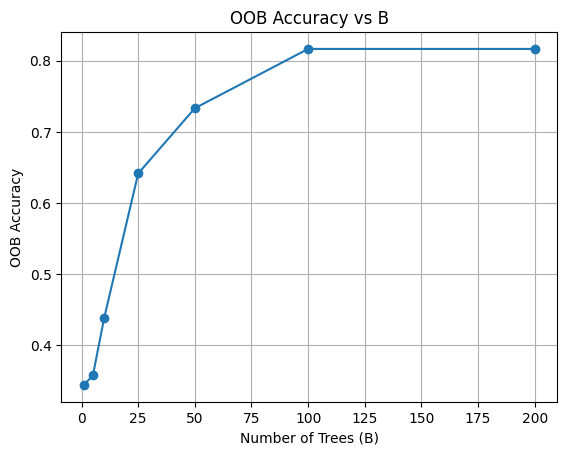

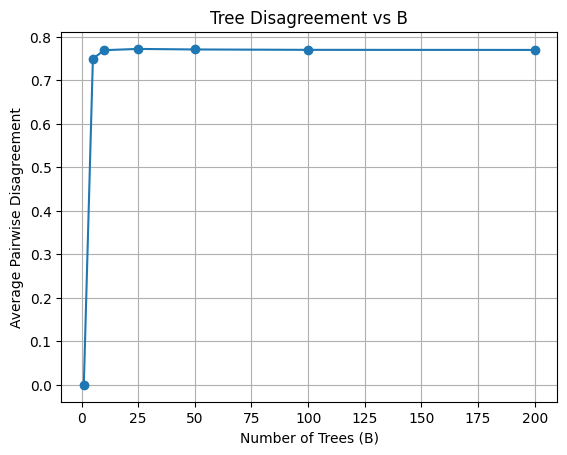

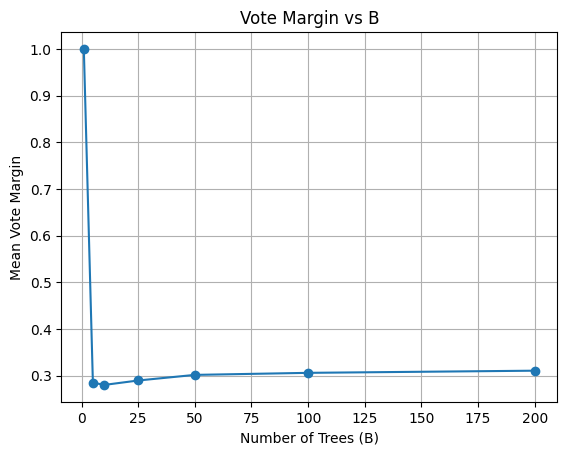

In [ ]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(q1c_df["B"], q1c_df["OOB Accuracy"], marker="o")
plt.xlabel("Number of Trees (B)")
plt.ylabel("OOB Accuracy")
plt.title("OOB Accuracy vs B")
plt.grid()
plt.show()

plt.figure()
plt.plot(q1c_df["B"], q1c_df["Disagreement"], marker="o")
plt.xlabel("Number of Trees (B)")
plt.ylabel("Average Pairwise Disagreement")
plt.title("Tree Disagreement vs B")
plt.grid()
plt.show()

plt.figure()
plt.plot(q1c_df["B"], q1c_df["Vote Margin"], marker="o")
plt.xlabel("Number of Trees (B)")
plt.ylabel("Mean Vote Margin")
plt.title("Vote Margin vs B")
plt.grid()
plt.show()

In [ ]:
best_val = bagging_df["Val Acc"].max()

best_B_values = bagging_df[
    bagging_df["Val Acc"] == best_val
]["B"]

final_B = int(best_B_values.min())

final_bagged_trees = bagged_trees[:final_B]

print("Final B:", final_B)
print("Best validation accuracy:", round(best_val, 4))

Final B: 100
Best validation accuracy: 0.8875


### Q1(c) Observation

OOB accuracy estimates performance using training samples excluded from individual bootstrap sets.

Disagreement measures how differently the trees behave. Some disagreement is useful because bagging benefits from diverse trees.

Vote margin measures ensemble confidence. A larger margin means the winning class receives much more support than the second class.

These measures do not necessarily change in exactly the same way. Final B is selected only using validation accuracy.

## Q1(d) Clean vs Masked Test Set

Compare the frozen single tree and final bagged model on clean and masked test images.

Also inspect:
- 2 faces where bagging corrects the tree
- 2 faces where both models are wrong

In [ ]:
X_test_img = X_test.reshape(-1, 64, 64).copy()

X_test_masked_img = X_test_img.copy()
X_test_masked_img[:, 24:40, 24:40] = 0

X_test_masked = X_test_masked_img.reshape(len(X_test), -1)

print("Clean test:", X_test.shape)
print("Masked test:", X_test_masked.shape)

Clean test: (80, 4096)
Masked test: (80, 4096)


In [ ]:
tree_clean_pred = frozen_tree.predict(X_test)
tree_mask_pred = frozen_tree.predict(X_test_masked)

tree_clean_prob = frozen_tree.predict_proba(X_test)
tree_mask_prob = frozen_tree.predict_proba(X_test_masked)

tree_clean_conf = tree_clean_prob.max(axis=1)
tree_mask_conf = tree_mask_prob.max(axis=1)

print("Tree clean accuracy:",
      round(accuracy_score(y_test, tree_clean_pred), 4))

print("Tree masked accuracy:",
      round(accuracy_score(y_test, tree_mask_pred), 4))

Tree clean accuracy: 0.5
Tree masked accuracy: 0.375


In [ ]:
bag_clean_preds = np.array([
    tree.predict(X_test)
    for tree in final_bagged_trees
])

bag_mask_preds = np.array([
    tree.predict(X_test_masked)
    for tree in final_bagged_trees
])

bag_clean_pred = majority_vote(
    bag_clean_preds,
    n_classes
)

bag_mask_pred = majority_vote(
    bag_mask_preds,
    n_classes
)

In [ ]:
def bagging_confidence(predictions):

    confidence = []

    for i in range(predictions.shape[1]):

        votes = np.bincount(
            predictions[:, i],
            minlength=n_classes
        )

        confidence.append(
            votes.max() / predictions.shape[0]
        )

    return np.array(confidence)


bag_clean_conf = bagging_confidence(bag_clean_preds)
bag_mask_conf = bagging_confidence(bag_mask_preds)

In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "Single Tree",
        "Single Tree",
        "Bagging",
        "Bagging"
    ],

    "Test Set": [
        "Clean",
        "Masked",
        "Clean",
        "Masked"
    ],

    "Accuracy": [
        accuracy_score(y_test, tree_clean_pred),
        accuracy_score(y_test, tree_mask_pred),
        accuracy_score(y_test, bag_clean_pred),
        accuracy_score(y_test, bag_mask_pred)
    ],

    "Mean Confidence": [
        tree_clean_conf.mean(),
        tree_mask_conf.mean(),
        bag_clean_conf.mean(),
        bag_mask_conf.mean()
    ]
})

comparison.round(4)

,Model,Test Set,Accuracy,Mean Confidence
0,Single Tree,Clean,0.500,1.0000
1,Single Tree,Masked,0.375,1.0000
2,Bagging,Clean,0.800,0.3915
3,Bagging,Masked,0.700,0.2782


In [ ]:
bag_corrects = np.where(
    (tree_clean_pred != y_test) &
    (bag_clean_pred == y_test)
)[0]

both_wrong = np.where(
    (tree_clean_pred != y_test) &
    (bag_clean_pred != y_test)
)[0]

corrected_examples = bag_corrects[:2]
wrong_examples = both_wrong[:2]

print("Bagging corrects tree:", corrected_examples)
print("Both wrong:", wrong_examples)

Bagging corrects tree: [2 5]
Both wrong: [0 1]


In [ ]:
selected = list(corrected_examples) + list(wrong_examples)

for idx in selected:

    votes = np.bincount(
        bag_clean_preds[:, idx],
        minlength=n_classes
    )

    vote_counts = {
        cls: int(v)
        for cls, v in enumerate(votes)
        if v > 0
    }

    print("\nTest index:", idx)
    print("True class:", y_test[idx])
    print("Tree prediction:", tree_clean_pred[idx])
    print("Bagging prediction:", bag_clean_pred[idx])
    print("Bagging votes:", vote_counts)


Test index: 2
True class: 1
Tree prediction: 11
Bagging prediction: 1
Bagging votes: {0: 2, 1: 38, 3: 15, 5: 1, 7: 1, 8: 1, 9: 2, 10: 2, 12: 5, 13: 2, 14: 1, 17: 1, 18: 1, 19: 1, 20: 2, 25: 1, 26: 3, 30: 10, 31: 3, 33: 3, 34: 1, 35: 1, 37: 2, 38: 1}

Test index: 5
True class: 2
Tree prediction: 17
Bagging prediction: 2
Bagging votes: {0: 1, 1: 2, 2: 31, 3: 4, 4: 2, 5: 1, 6: 1, 8: 1, 9: 7, 11: 3, 12: 4, 13: 2, 16: 1, 17: 4, 19: 1, 21: 1, 22: 6, 24: 1, 25: 4, 26: 1, 27: 3, 28: 1, 34: 2, 35: 1, 37: 6, 39: 9}

Test index: 0
True class: 0
Tree prediction: 26
Bagging prediction: 26
Bagging votes: {0: 18, 3: 4, 4: 3, 5: 2, 7: 9, 8: 2, 10: 3, 11: 2, 12: 2, 13: 1, 14: 1, 15: 17, 16: 2, 17: 2, 23: 2, 25: 1, 26: 24, 31: 1, 35: 1, 37: 1, 39: 2}

Test index: 1
True class: 0
Tree prediction: 25
Bagging prediction: 15
Bagging votes: {0: 6, 1: 14, 2: 2, 3: 4, 4: 2, 5: 3, 7: 12, 8: 5, 10: 1, 11: 1, 12: 1, 13: 2, 14: 1, 15: 17, 17: 1, 21: 2, 22: 2, 25: 3, 27: 1, 28: 2, 29: 1, 30: 7, 31: 5, 33: 1, 34: 2

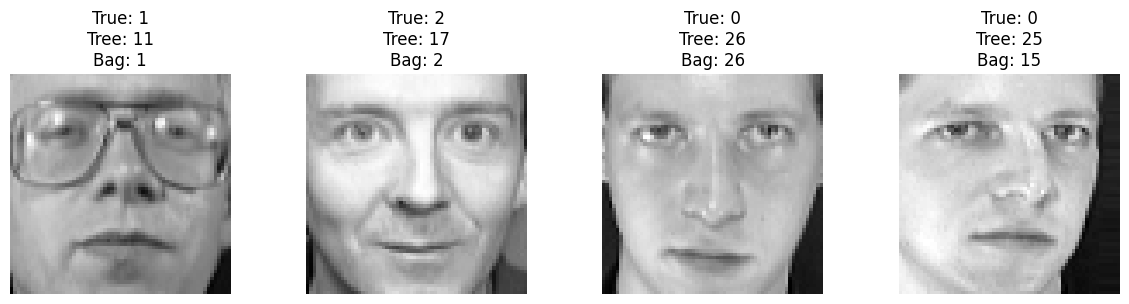

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(selected), figsize=(12, 3))

for ax, idx in zip(axes, selected):

    ax.imshow(
        X_test[idx].reshape(64, 64),
        cmap="gray"
    )

    ax.set_title(
        f"True: {y_test[idx]}\n"
        f"Tree: {tree_clean_pred[idx]}\n"
        f"Bag: {bag_clean_pred[idx]}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

### Q1(d) Observation

Bagging can correct errors caused by an unstable individual tree because several trees vote together.

If different bootstrap trees make different mistakes, majority voting can recover the correct class.

However, if most trees make the same wrong prediction, bagging cannot correct the error. Such errors may come from insufficient or confusing image information.

The masked test set also shows how removing the centre region affects model accuracy and confidence.

In [ ]:
import numpy as np
import pandas as pd

from sklearn.tree import DecisionTreeClassifier


In [ ]:
X_toy = np.array([
    [0.0, 0.0],
    [0.5, 0.2],
    [1.0, 0.0],
    [1.5, 0.5],
    [2.0, 1.0],
    [2.5, 1.2],
    [3.0, 2.0],
    [3.5, 2.2],
    [4.0, 3.0]
])

y_toy = np.array([
    0, 0, 0,
    1, 1, 1,
    2, 2, 2
])

print("Samples:", len(X_toy))
print("Classes:", np.unique(y_toy))

Samples: 9
Classes: [0 1 2]


In [ ]:
n = len(X_toy)

weights = np.ones(n) / n

print("Initial weights:")
print(np.round(weights, 4))

print("Sum:", weights.sum())

Initial weights:
[0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111 0.1111]
Sum: 1.0


In [ ]:
weak_tree = DecisionTreeClassifier(
    max_depth=1,
    random_state=seed
)

weak_tree.fit(
    X_toy,
    y_toy,
    sample_weight=weights
)

pred = weak_tree.predict(X_toy)

print("True labels :", y_toy)
print("Predictions :", pred)

True labels : [0 0 0 1 1 1 2 2 2]
Predictions : [0 0 0 1 1 1 1 1 1]


In [ ]:
wrong = (pred != y_toy)

weighted_error = np.sum(
    weights * wrong
)

print("Wrong predictions:", wrong.astype(int))
print("Weighted error:", round(weighted_error, 4))

Wrong predictions: [0 0 0 0 0 0 1 1 1]
Weighted error: 0.3333


In [ ]:
K = len(np.unique(y_toy))

random_limit = 1 - (1 / K)

if weighted_error >= random_limit:
    print("Weak learner is not better than random prediction.")
    alpha = None

elif weighted_error <= 0:
    alpha = 1.0
    print("Perfect weak learner.")

else:
    alpha = (
        np.log((1 - weighted_error) / weighted_error)
        + np.log(K - 1)
    )

print("Random limit:", round(random_limit, 4))
print("Alpha:", alpha)

Random limit: 0.6667
Alpha: 1.3862943611198908


In [ ]:
new_weights = weights.copy()

if alpha is not None:

    new_weights *= np.exp(
        alpha * wrong
    )

    new_weights /= new_weights.sum()

print("Updated weights:")
print(np.round(new_weights, 4))

print("Sum:", round(new_weights.sum(), 4))

Updated weights:
[0.0556 0.0556 0.0556 0.0556 0.0556 0.0556 0.2222 0.2222 0.2222]
Sum: 1.0


In [ ]:
round_log = pd.DataFrame({
    "Sample": np.arange(len(X_toy)),
    "True": y_toy,
    "Prediction": pred,
    "Wrong": wrong.astype(int),
    "Initial Weight": weights,
    "Updated Weight": new_weights
})

print("Weighted error =", round(weighted_error, 4))
print("Alpha =", round(alpha, 4))

round_log.round(4)

Weighted error = 0.3333
Alpha = 1.3863


,Sample,True,Prediction,Wrong,Initial Weight,Updated Weight
0,0,0,0,0,0.1111,0.0556
1,1,0,0,0,0.1111,0.0556
2,2,0,0,0,0.1111,0.0556
3,3,1,1,0,0.1111,0.0556
4,4,1,1,0,0.1111,0.0556
5,5,1,1,0,0.1111,0.0556
6,6,2,1,1,0.1111,0.2222
7,7,2,1,1,0.1111,0.2222
8,8,2,1,1,0.1111,0.2222


In [ ]:
def samme_round(X, y, weights, depth, random_state):

    K = len(np.unique(y))

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=random_state
    )

    model.fit(
        X,
        y,
        sample_weight=weights
    )

    pred = model.predict(X)

    wrong = (pred != y)

    error = np.sum(
        weights * wrong
    )

    random_limit = 1 - (1 / K)

    if error >= random_limit:
        return None, None, error, weights

    error = np.clip(error, 1e-12, 1 - 1e-12)

    alpha = (
        np.log((1 - error) / error)
        + np.log(K - 1)
    )

    new_weights = weights * np.exp(
        alpha * wrong
    )

    new_weights /= new_weights.sum()

    return model, alpha, error, new_weights

In [ ]:
#Q2(a) only. The assignment asks us to implement SAMME AdaBoost from scratch,

In [ ]:
def samme_predict(models, alphas, X, n_classes=40):

    scores = np.zeros((len(X), n_classes))

    for model, alpha in zip(models, alphas):
        pred = model.predict(X)

        for k in range(n_classes):
            scores[:, k] += alpha * (pred == k)

    return np.argmax(scores, axis=1)

In [ ]:
def train_samme(X, y, depth, max_rounds, seed):

    n = len(y)
    K = len(np.unique(y))

    weights = np.ones(n) / n

    models = []
    alphas = []

    error_history = []
    alpha_history = []
    max_weight_history = []
    top10_weight_history = []

    for t in range(max_rounds):

        model = DecisionTreeClassifier(
            max_depth=depth,
            random_state=seed + t
        )

        model.fit(X, y, sample_weight=weights)

        pred = model.predict(X)
        wrong = (pred != y)

        error = np.sum(weights * wrong)

        # Weak learner must be better than random
        if error >= 1 - (1 / K):
            break

        error = np.clip(error, 1e-12, 1 - 1e-12)

        alpha = (
            np.log((1 - error) / error)
            + np.log(K - 1)
        )

        models.append(model)
        alphas.append(alpha)

        error_history.append(error)
        alpha_history.append(alpha)

        weights *= np.exp(alpha * wrong)
        weights /= weights.sum()

        max_weight_history.append(weights.max())

        top10 = np.sort(weights)[-10:]
        top10_weight_history.append(top10.sum())

    return {
        "models": models,
        "alphas": np.array(alphas),
        "errors": np.array(error_history),
        "max_weights": np.array(max_weight_history),
        "top10_weights": np.array(top10_weight_history)
    }

In [ ]:
depths = [1, 2, 3, 4]

boost_models = {}

for depth in depths:

    boost_models[depth] = train_samme(
        X_train,
        y_train,
        depth=depth,
        max_rounds=100,
        seed=seed
    )

    print(
        "Depth:", depth,
        "Rounds trained:",
        len(boost_models[depth]["models"])
    )

Depth: 1 Rounds trained: 100
Depth: 2 Rounds trained: 100
Depth: 3 Rounds trained: 100
Depth: 4 Rounds trained: 100


In [ ]:
round_values = [10, 25, 50, 100]

boost_results = []

for depth in depths:

    data = boost_models[depth]

    for rounds in round_values:

        R = min(rounds, len(data["models"]))

        if R == 0:
            continue

        models = data["models"][:R]
        alphas = data["alphas"][:R]

        train_pred = samme_predict(
            models, alphas, X_train, n_classes
        )

        val_pred = samme_predict(
            models, alphas, X_val, n_classes
        )

        test_pred = samme_predict(
            models, alphas, X_test, n_classes
        )

        boost_results.append([
            depth,
            rounds,
            accuracy_score(y_train, train_pred),
            accuracy_score(y_val, val_pred),
            accuracy_score(y_test, test_pred)
        ])

In [ ]:
boost_df = pd.DataFrame(
    boost_results,
    columns=[
        "Depth",
        "Rounds",
        "Train Acc",
        "Val Acc",
        "Test Acc"
    ]
)

boost_df.round(4)

,Depth,Rounds,Train Acc,Val Acc,Test Acc
0,1,10,0.0500,0.0375,0.0500
1,1,25,0.0917,0.0625,0.0875
2,1,50,0.1542,0.0500,0.0750
3,1,100,0.1417,0.1250,0.1000
4,2,10,0.1208,0.0750,0.0500
5,2,25,0.1917,0.1375,0.1000
6,2,50,0.4458,0.2750,0.2250
7,2,100,0.4458,0.1875,0.1500
8,3,10,0.1542,0.0750,0.1000
9,3,25,0.4042,0.2375,0.2375


In [ ]:
best_idx = boost_df["Val Acc"].idxmax()
best_boost = boost_df.loc[best_idx]

selected_depth = int(best_boost["Depth"])
selected_rounds = int(best_boost["Rounds"])

print("Selected depth:", selected_depth)
print("Selected rounds:", selected_rounds)
print("Validation accuracy:",
      round(best_boost["Val Acc"], 4))

Selected depth: 4
Selected rounds: 100
Validation accuracy: 0.35


In [ ]:
selected_data = boost_models[selected_depth]

selected_boost_models = (
    selected_data["models"][:selected_rounds]
)

selected_boost_alphas = (
    selected_data["alphas"][:selected_rounds]
)

print("Final depth:", selected_depth)
print("Final rounds:", len(selected_boost_models))

Final depth: 4
Final rounds: 100


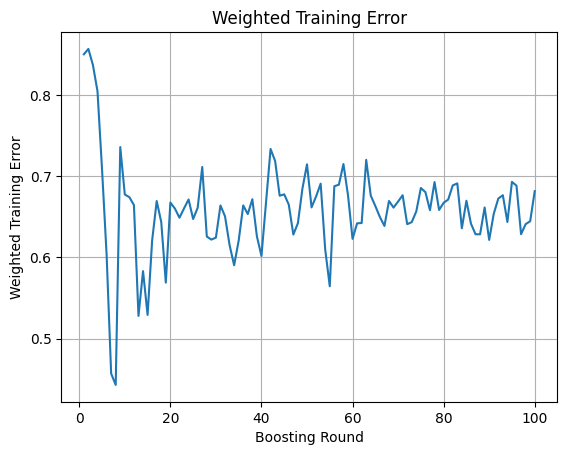

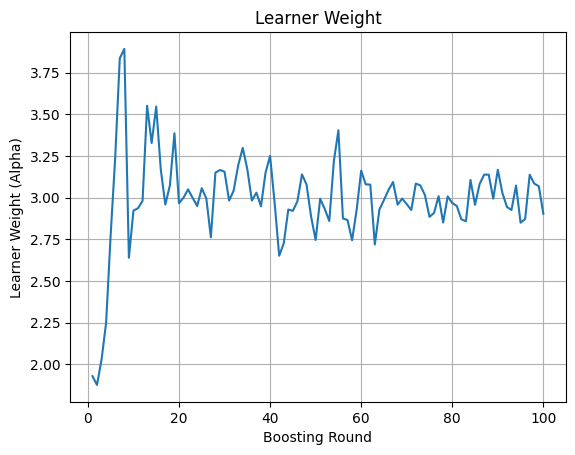

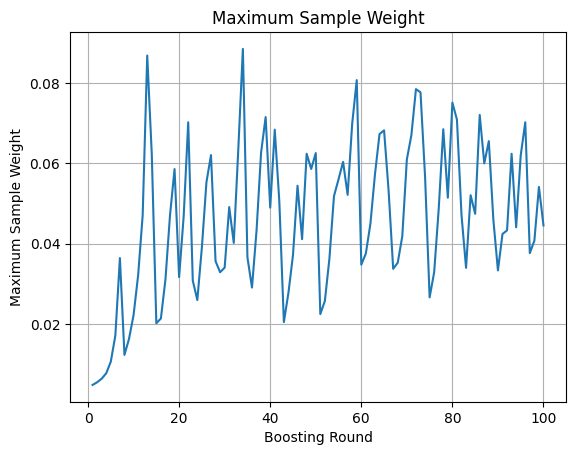

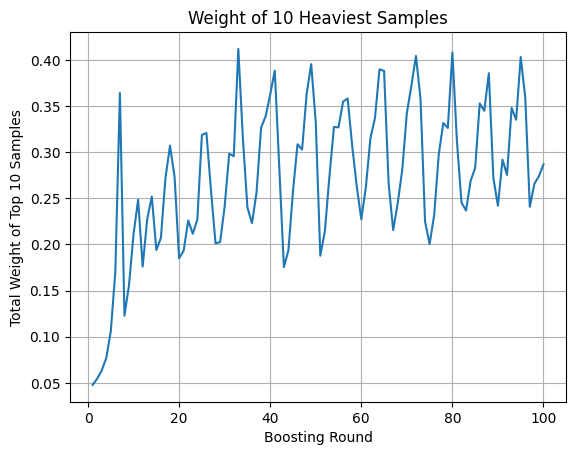

In [ ]:
import matplotlib.pyplot as plt

R = len(selected_boost_models)

errors = selected_data["errors"][:R]
alphas = selected_data["alphas"][:R]
max_weights = selected_data["max_weights"][:R]
top10_weights = selected_data["top10_weights"][:R]

rounds = np.arange(1, R + 1)

plt.figure()
plt.plot(rounds, errors)
plt.xlabel("Boosting Round")
plt.ylabel("Weighted Training Error")
plt.title("Weighted Training Error")
plt.grid()
plt.show()

plt.figure()
plt.plot(rounds, alphas)
plt.xlabel("Boosting Round")
plt.ylabel("Learner Weight (Alpha)")
plt.title("Learner Weight")
plt.grid()
plt.show()

plt.figure()
plt.plot(rounds, max_weights)
plt.xlabel("Boosting Round")
plt.ylabel("Maximum Sample Weight")
plt.title("Maximum Sample Weight")
plt.grid()
plt.show()

plt.figure()
plt.plot(rounds, top10_weights)
plt.xlabel("Boosting Round")
plt.ylabel("Total Weight of Top 10 Samples")
plt.title("Weight of 10 Heaviest Samples")
plt.grid()
plt.show()

In [ ]:
## Q2(b) SAMME on Olivetti Faces

In [ ]:
def samme_predict(models, alphas, X, n_classes=40):

    scores = np.zeros((len(X), n_classes))

    for model, alpha in zip(models, alphas):

        pred = model.predict(X)

        for k in range(n_classes):
            scores[:, k] += alpha * (pred == k)

    return np.argmax(scores, axis=1)

In [ ]:
def train_samme(X, y, depth, max_rounds, seed):

    n = len(y)
    K = len(np.unique(y))

    weights = np.ones(n) / n

    models = []
    alphas = []

    error_history = []
    alpha_history = []
    max_weight_history = []
    top10_weight_history = []

    for t in range(max_rounds):

        model = DecisionTreeClassifier(
            max_depth=depth,
            random_state=seed + t
        )

        model.fit(
            X,
            y,
            sample_weight=weights
        )

        pred = model.predict(X)
        wrong = (pred != y)

        error = np.sum(
            weights * wrong
        )

        # SAMME weak learner condition
        random_limit = 1 - (1 / K)

        if error >= random_limit:
            print("Stopped at round", t + 1,
                  "- learner not better than random")
            break

        error = np.clip(
            error,
            1e-12,
            1 - 1e-12
        )

        alpha = (
            np.log((1 - error) / error)
            + np.log(K - 1)
        )

        models.append(model)
        alphas.append(alpha)

        error_history.append(error)
        alpha_history.append(alpha)

        # Update sample weights
        weights = weights * np.exp(
            alpha * wrong
        )

        weights = weights / weights.sum()

        max_weight_history.append(
            weights.max()
        )

        top10_weight_history.append(
            np.sort(weights)[-10:].sum()
        )

    return {
        "models": models,
        "alphas": np.array(alphas),
        "errors": np.array(error_history),
        "max_weights": np.array(max_weight_history),
        "top10_weights": np.array(top10_weight_history)
    }

In [ ]:
depth_values_boost = [1, 2, 3, 4]

boost_models = {}

for depth in depth_values_boost:

    boost_models[depth] = train_samme(
        X_train,
        y_train,
        depth=depth,
        max_rounds=100,
        seed=seed
    )

    print(
        "Depth:", depth,
        "| Trained rounds:",
        len(boost_models[depth]["models"])
    )

Depth: 1 | Trained rounds: 100
Depth: 2 | Trained rounds: 100
Depth: 3 | Trained rounds: 100
Depth: 4 | Trained rounds: 100


In [ ]:
round_values = [10, 25, 50, 100]

boost_results = []

for depth in depth_values_boost:

    data = boost_models[depth]

    for rounds in round_values:

        used_rounds = min(
            rounds,
            len(data["models"])
        )

        if used_rounds == 0:
            continue

        models_now = data["models"][:used_rounds]
        alphas_now = data["alphas"][:used_rounds]

        train_pred = samme_predict(
            models_now,
            alphas_now,
            X_train
        )

        val_pred = samme_predict(
            models_now,
            alphas_now,
            X_val
        )

        test_pred = samme_predict(
            models_now,
            alphas_now,
            X_test
        )

        boost_results.append([
            depth,
            rounds,
            used_rounds,
            accuracy_score(y_train, train_pred),
            accuracy_score(y_val, val_pred),
            accuracy_score(y_test, test_pred)
        ])

In [ ]:
boost_df = pd.DataFrame(
    boost_results,
    columns=[
        "Depth",
        "Rounds",
        "Used Rounds",
        "Train Acc",
        "Val Acc",
        "Test Acc"
    ]
)

boost_df.round(4)

,Depth,Rounds,Used Rounds,Train Acc,Val Acc,Test Acc
0,1,10,10,0.0500,0.0375,0.0500
1,1,25,25,0.0917,0.0625,0.0875
2,1,50,50,0.1542,0.0500,0.0750
3,1,100,100,0.1417,0.1250,0.1000
4,2,10,10,0.1208,0.0750,0.0500
5,2,25,25,0.1917,0.1375,0.1000
6,2,50,50,0.4458,0.2750,0.2250
7,2,100,100,0.4458,0.1875,0.1500
8,3,10,10,0.1542,0.0750,0.1000
9,3,25,25,0.4042,0.2375,0.2375


In [ ]:
best_boost_idx = boost_df["Val Acc"].idxmax()

best_boost_row = boost_df.loc[
    best_boost_idx
]

selected_depth = int(
    best_boost_row["Depth"]
)

selected_rounds = int(
    best_boost_row["Used Rounds"]
)

selected_data = boost_models[
    selected_depth
]

selected_boost_models = (
    selected_data["models"][:selected_rounds]
)

selected_boost_alphas = (
    selected_data["alphas"][:selected_rounds]
)

print("Selected depth:", selected_depth)
print("Selected rounds:", selected_rounds)
print(
    "Validation accuracy:",
    round(best_boost_row["Val Acc"], 4)
)

Selected depth: 4
Selected rounds: 100
Validation accuracy: 0.35


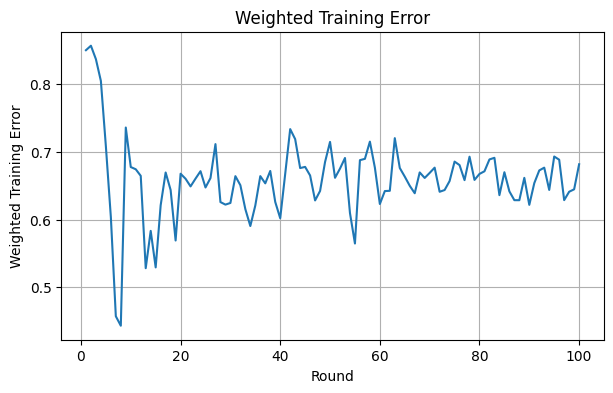

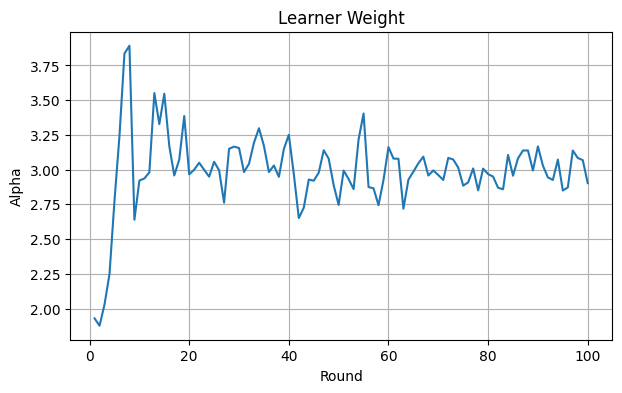

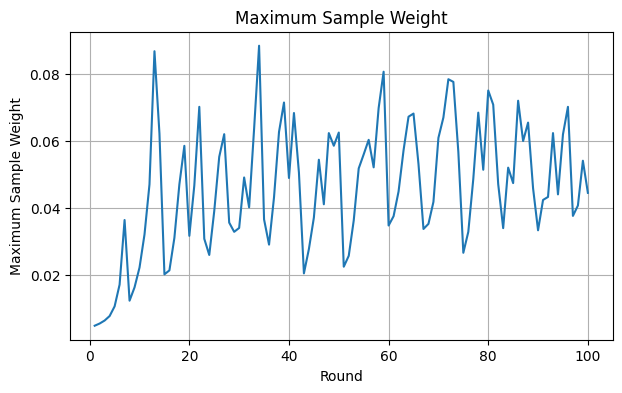

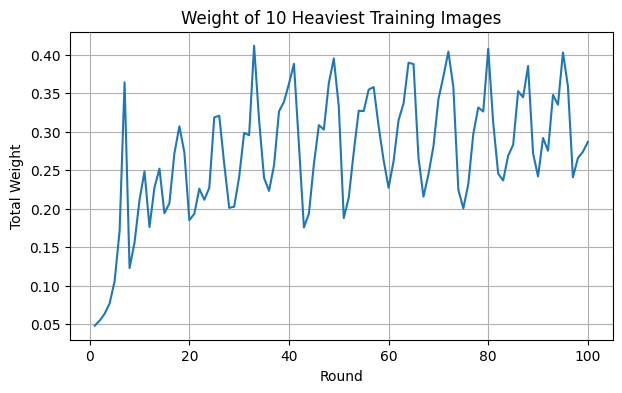

In [ ]:
R = selected_rounds

errors = selected_data["errors"][:R]
alphas = selected_data["alphas"][:R]
max_weights = selected_data["max_weights"][:R]
top10_weights = selected_data["top10_weights"][:R]

round_axis = np.arange(1, R + 1)


plt.figure(figsize=(7, 4))
plt.plot(round_axis, errors)
plt.xlabel("Round")
plt.ylabel("Weighted Training Error")
plt.title("Weighted Training Error")
plt.grid()
plt.show()


plt.figure(figsize=(7, 4))
plt.plot(round_axis, alphas)
plt.xlabel("Round")
plt.ylabel("Alpha")
plt.title("Learner Weight")
plt.grid()
plt.show()


plt.figure(figsize=(7, 4))
plt.plot(round_axis, max_weights)
plt.xlabel("Round")
plt.ylabel("Maximum Sample Weight")
plt.title("Maximum Sample Weight")
plt.grid()
plt.show()


plt.figure(figsize=(7, 4))
plt.plot(round_axis, top10_weights)
plt.xlabel("Round")
plt.ylabel("Total Weight")
plt.title("Weight of 10 Heaviest Training Images")
plt.grid()
plt.show()

In [ ]:
selected_depth
selected_rounds
selected_boost_models
selected_boost_alphas
boost_df

,Depth,Rounds,Used Rounds,Train Acc,Val Acc,Test Acc
0,1,10,10,0.050000,0.0375,0.0500
1,1,25,25,0.091667,0.0625,0.0875
2,1,50,50,0.154167,0.0500,0.0750
3,1,100,100,0.141667,0.1250,0.1000
4,2,10,10,0.120833,0.0750,0.0500
5,2,25,25,0.191667,0.1375,0.1000
6,2,50,50,0.445833,0.2750,0.2250
7,2,100,100,0.445833,0.1875,0.1500
8,3,10,10,0.154167,0.0750,0.1000
9,3,25,25,0.404167,0.2375,0.2375


In [ ]:
## Q2(c) Bagging vs Boosting

In [ ]:
# Select final B using validation accuracy only

best_bag_val = bagging_df["Val Acc"].max()

candidate_B = bagging_df.loc[
    bagging_df["Val Acc"] == best_bag_val,
    "B"
]

final_B = int(candidate_B.min())

final_bagged_trees = bagged_trees[:final_B]

print("Final Bagging B:", final_B)
print("Best validation accuracy:", round(best_bag_val, 4))

Final Bagging B: 100
Best validation accuracy: 0.8875


In [ ]:
import time

def predict_bagging(models, X):

    preds = np.array([
        model.predict(X)
        for model in models
    ])

    return majority_vote(preds)


def train_bagging_timed(B):

    rng_local = np.random.default_rng(seed)

    models = []

    start = time.perf_counter()

    for b in range(B):

        boot_idx = rng_local.choice(
            len(X_train),
            size=len(X_train),
            replace=True
        )

        model = DecisionTreeClassifier(
            max_depth=best_depth,
            min_samples_leaf=best_min_leaf,
            random_state=seed + b
        )

        model.fit(
            X_train[boot_idx],
            y_train[boot_idx]
        )

        models.append(model)

    elapsed = time.perf_counter() - start

    return models, elapsed

In [ ]:
def train_boosting_timed(rounds):

    start = time.perf_counter()

    result = train_samme(
        X_train,
        y_train,
        depth=selected_depth,
        max_rounds=rounds,
        seed=seed
    )

    elapsed = time.perf_counter() - start

    return result, elapsed

In [ ]:
q2c_results = []

for B in [25, 50, 100]:

    # BAGGING
    bag_models_B, bag_time = train_bagging_timed(B)

    bag_train_pred = predict_bagging(
        bag_models_B, X_train
    )

    bag_val_pred = predict_bagging(
        bag_models_B, X_val
    )

    bag_test_pred = predict_bagging(
        bag_models_B, X_test
    )

    q2c_results.append([
        "Bagging",
        B,
        accuracy_score(y_train, bag_train_pred),
        accuracy_score(y_val, bag_val_pred),
        accuracy_score(y_test, bag_test_pred),
        bag_time
    ])


    # BOOSTING
    boost_data_B, boost_time = train_boosting_timed(B)

    boost_models_B = boost_data_B["models"]
    boost_alphas_B = boost_data_B["alphas"]

    boost_train_pred = samme_predict(
        boost_models_B,
        boost_alphas_B,
        X_train
    )

    boost_val_pred = samme_predict(
        boost_models_B,
        boost_alphas_B,
        X_val
    )

    boost_test_pred = samme_predict(
        boost_models_B,
        boost_alphas_B,
        X_test
    )

    q2c_results.append([
        "Boosting",
        len(boost_models_B),
        accuracy_score(y_train, boost_train_pred),
        accuracy_score(y_val, boost_val_pred),
        accuracy_score(y_test, boost_test_pred),
        boost_time
    ])

In [ ]:
q2c_df = pd.DataFrame(
    q2c_results,
    columns=[
        "Model",
        "Learners",
        "Train Acc",
        "Val Acc",
        "Test Acc",
        "Training Time (s)"
    ]
)

q2c_df.round(4)

,Model,Learners,Train Acc,Val Acc,Test Acc,Training Time (s)
0,Bagging,25,1.0000,0.8125,0.7625,53.3559
1,Boosting,25,0.6042,0.2875,0.2500,15.4597
2,Bagging,50,1.0000,0.8375,0.8000,106.7422
3,Boosting,50,0.7333,0.3000,0.3125,32.0006
4,Bagging,100,1.0000,0.8875,0.8000,212.6954
5,Boosting,100,0.9500,0.3500,0.3625,63.1004


In [ ]:
R = len(selected_boost_models)

weights = np.ones(len(X_train)) / len(X_train)

weight_history = []
prediction_history = []

for model, alpha in zip(
    selected_boost_models,
    selected_boost_alphas
):

    pred = model.predict(X_train)

    wrong = (pred != y_train)

    prediction_history.append(
        pred.copy()
    )

    weights = weights * np.exp(
        alpha * wrong
    )

    weights = weights / weights.sum()

    weight_history.append(
        weights.copy()
    )


weight_history = np.array(weight_history)
prediction_history = np.array(prediction_history)

max_pos = np.unravel_index(
    np.argmax(weight_history),
    weight_history.shape
)

high_round = max_pos[0]
high_idx = max_pos[1]

print("Training index:", high_idx)
print("True class:", y_train[high_idx])
print("Maximum weight:",
      round(weight_history[high_round, high_idx], 5))
print("Maximum at round:", high_round + 1)

Training index: 36
True class: 6
Maximum weight: 0.08856
Maximum at round: 34


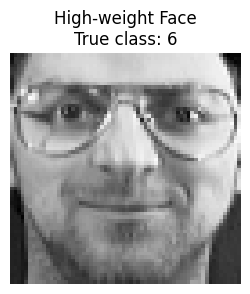

,Round,Prediction,Correct,Weight
0,1,0,False,0.004779
1,2,1,False,0.005440
2,3,2,False,0.006338
3,4,6,True,0.000811
4,5,4,False,0.001116
...,...,...,...,...
95,96,3,False,0.007582
96,97,35,False,0.011760
97,98,20,False,0.017886
98,99,8,False,0.027053


In [ ]:
plt.figure(figsize=(3, 3))

plt.imshow(
    X_train[high_idx].reshape(64, 64),
    cmap="gray"
)

plt.title(
    f"High-weight Face\nTrue class: {y_train[high_idx]}"
)

plt.axis("off")
plt.show()


high_face_history = pd.DataFrame({
    "Round": np.arange(1, R + 1),

    "Prediction":
        prediction_history[:, high_idx],

    "Correct":
        prediction_history[:, high_idx]
        == y_train[high_idx],

    "Weight":
        weight_history[:, high_idx]
})

high_face_history

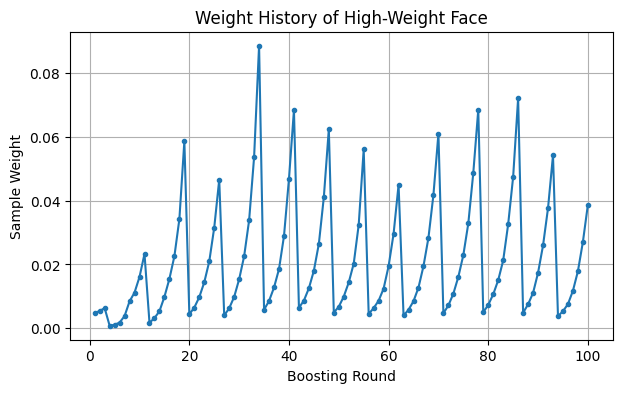

In [ ]:
plt.figure(figsize=(7, 4))

plt.plot(
    np.arange(1, R + 1),
    weight_history[:, high_idx],
    marker="o",
    markersize=3
)

plt.xlabel("Boosting Round")
plt.ylabel("Sample Weight")
plt.title("Weight History of High-Weight Face")
plt.grid()

plt.show()

In [ ]:
## Q2(d) Final Clean vs Masked Comparison

In [ ]:
tree_clean_pred = frozen_tree.predict(X_test)
tree_mask_pred = frozen_tree.predict(X_test_masked)

tree_clean_prob = frozen_tree.predict_proba(X_test)
tree_mask_prob = frozen_tree.predict_proba(X_test_masked)

tree_clean_conf = tree_clean_prob.max(axis=1)
tree_mask_conf = tree_mask_prob.max(axis=1)

In [ ]:
bag_clean_preds = np.array([
    model.predict(X_test)
    for model in final_bagged_trees
])

bag_mask_preds = np.array([
    model.predict(X_test_masked)
    for model in final_bagged_trees
])


bag_clean_pred = majority_vote(
    bag_clean_preds
)

bag_mask_pred = majority_vote(
    bag_mask_preds
)


def bagging_confidence(predictions):

    conf = []

    B = predictions.shape[0]

    for i in range(predictions.shape[1]):

        votes = np.bincount(
            predictions[:, i],
            minlength=40
        )

        conf.append(
            votes.max() / B
        )

    return np.array(conf)


bag_clean_conf = bagging_confidence(
    bag_clean_preds
)

bag_mask_conf = bagging_confidence(
    bag_mask_preds
)

In [ ]:
def samme_scores(models, alphas, X):

    scores = np.zeros(
        (len(X), 40)
    )

    total_alpha = np.sum(alphas)

    for model, alpha in zip(
        models,
        alphas
    ):

        pred = model.predict(X)

        for k in range(40):

            scores[:, k] += (
                alpha * (pred == k)
            )

    return scores / total_alpha

In [ ]:
boost_clean_scores = samme_scores(
    selected_boost_models,
    selected_boost_alphas,
    X_test
)

boost_mask_scores = samme_scores(
    selected_boost_models,
    selected_boost_alphas,
    X_test_masked
)


boost_clean_pred = np.argmax(
    boost_clean_scores,
    axis=1
)

boost_mask_pred = np.argmax(
    boost_mask_scores,
    axis=1
)


boost_clean_conf = boost_clean_scores.max(
    axis=1
)

boost_mask_conf = boost_mask_scores.max(
    axis=1
)

In [ ]:
q2d_table = pd.DataFrame({

    "Model": [
        "Single Tree",
        "Single Tree",
        "Bagging",
        "Bagging",
        "Boosting",
        "Boosting"
    ],

    "Test Set": [
        "Clean",
        "Masked",
        "Clean",
        "Masked",
        "Clean",
        "Masked"
    ],

    "Accuracy": [

        accuracy_score(
            y_test,
            tree_clean_pred
        ),

        accuracy_score(
            y_test,
            tree_mask_pred
        ),

        accuracy_score(
            y_test,
            bag_clean_pred
        ),

        accuracy_score(
            y_test,
            bag_mask_pred
        ),

        accuracy_score(
            y_test,
            boost_clean_pred
        ),

        accuracy_score(
            y_test,
            boost_mask_pred
        )
    ],

    "Mean Confidence": [

        tree_clean_conf.mean(),
        tree_mask_conf.mean(),

        bag_clean_conf.mean(),
        bag_mask_conf.mean(),

        boost_clean_conf.mean(),
        boost_mask_conf.mean()
    ]
})

q2d_table.round(4)

,Model,Test Set,Accuracy,Mean Confidence
0,Single Tree,Clean,0.5000,1.0000
1,Single Tree,Masked,0.3750,1.0000
2,Bagging,Clean,0.8000,0.3915
3,Bagging,Masked,0.7000,0.2782
4,Boosting,Clean,0.3625,0.1320
5,Boosting,Masked,0.3750,0.1285


In [ ]:
different_cases = []

for i in range(len(y_test)):

    bag_clean_ok = (
        bag_clean_pred[i] == y_test[i]
    )

    bag_mask_ok = (
        bag_mask_pred[i] == y_test[i]
    )

    boost_clean_ok = (
        boost_clean_pred[i] == y_test[i]
    )

    boost_mask_ok = (
        boost_mask_pred[i] == y_test[i]
    )

    bag_changed = (
        bag_clean_ok != bag_mask_ok
    )

    boost_changed = (
        boost_clean_ok != boost_mask_ok
    )

    if bag_changed != boost_changed:
        different_cases.append(i)


if len(different_cases) > 0:

    diff_idx = different_cases[0]

else:

    bag_change = np.abs(
        bag_clean_conf - bag_mask_conf
    )

    boost_change = np.abs(
        boost_clean_conf - boost_mask_conf
    )

    diff_idx = np.argmax(
        np.abs(
            bag_change - boost_change
        )
    )


print("Selected test index:", diff_idx)
print("True class:", y_test[diff_idx])

print(
    "Bag clean/masked:",
    bag_clean_pred[diff_idx],
    bag_mask_pred[diff_idx]
)

print(
    "Boost clean/masked:",
    boost_clean_pred[diff_idx],
    boost_mask_pred[diff_idx]
)

Selected test index: 4
True class: 2
Bag clean/masked: 24 2
Boost clean/masked: 12 20


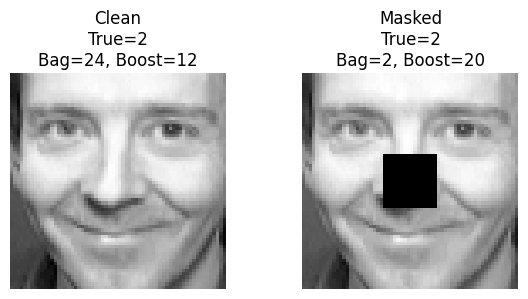

In [ ]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(6, 3)
)

axes[0].imshow(
    X_test[diff_idx].reshape(64, 64),
    cmap="gray"
)

axes[0].set_title(
    f"Clean\nTrue={y_test[diff_idx]}\n"
    f"Bag={bag_clean_pred[diff_idx]}, "
    f"Boost={boost_clean_pred[diff_idx]}"
)

axes[0].axis("off")


axes[1].imshow(
    X_test_masked[diff_idx].reshape(64, 64),
    cmap="gray"
)

axes[1].set_title(
    f"Masked\nTrue={y_test[diff_idx]}\n"
    f"Bag={bag_mask_pred[diff_idx]}, "
    f"Boost={boost_mask_pred[diff_idx]}"
)

axes[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Q3 Bias and Variance
## Q3(a)

In [ ]:
def make_resampled_train(rng_local):

    new_idx = []

    for person in range(40):

        person_positions = np.where(
            y_train == person
        )[0]

        sampled = rng_local.choice(
            person_positions,
            size=6,
            replace=True
        )

        new_idx.extend(sampled)

    new_idx = np.array(new_idx)

    return (
        X_train[new_idx],
        y_train[new_idx]
    )

In [ ]:
def one_hot_predictions(pred):

    return np.eye(40)[pred]


def bagging_vector(models, X):

    votes = np.zeros(
        (len(X), 40)
    )

    for model in models:

        pred = model.predict(X)

        for k in range(40):

            votes[:, k] += (
                pred == k
            )

    return votes / len(models)


def boosting_vector(models, alphas, X):

    scores = np.zeros(
        (len(X), 40)
    )

    for model, alpha in zip(
        models,
        alphas
    ):

        pred = model.predict(X)

        for k in range(40):

            scores[:, k] += (
                alpha * (pred == k)
            )

    return scores / np.sum(alphas)

In [ ]:
true_vectors = np.eye(40)[y_test]


def calculate_bias_variance(
    prediction_vectors,
    true_vectors
):

    P = np.array(
        prediction_vectors
    )

    p_bar = P.mean(axis=0)

    bias2 = np.mean(
        np.sum(
            (p_bar - true_vectors) ** 2,
            axis=1
        )
    )

    variance = np.mean(
        np.sum(
            (P - p_bar) ** 2,
            axis=2
        )
    )

    return bias2, variance

In [ ]:
R = 30

tree_vectors = []
bag_vectors = []
boost_vectors = []

tree_accs = []
bag_accs = []
boost_accs = []


for r in range(R):

    rng_r = np.random.default_rng(
        seed + 1000 + r
    )

    X_r, y_r = make_resampled_train(
        rng_r
    )


    # SINGLE TREE
    tree_r = DecisionTreeClassifier(
        max_depth=best_depth,
        min_samples_leaf=best_min_leaf,
        random_state=seed + r
    )

    tree_r.fit(
        X_r,
        y_r
    )

    pred_tree = tree_r.predict(
        X_test
    )

    tree_vectors.append(
        one_hot_predictions(
            pred_tree
        )
    )

    tree_accs.append(
        accuracy_score(
            y_test,
            pred_tree
        )
    )


    # BAGGING
    bag_models_r = []

    for b in range(final_B):

        boot_idx = rng_r.choice(
            len(X_r),
            size=len(X_r),
            replace=True
        )

        model = DecisionTreeClassifier(
            max_depth=best_depth,
            min_samples_leaf=best_min_leaf,
            random_state=
                seed + r * 1000 + b
        )

        model.fit(
            X_r[boot_idx],
            y_r[boot_idx]
        )

        bag_models_r.append(model)


    bag_prob = bagging_vector(
        bag_models_r,
        X_test
    )

    bag_vectors.append(
        bag_prob
    )

    bag_accs.append(
        accuracy_score(
            y_test,
            np.argmax(
                bag_prob,
                axis=1
            )
        )
    )


    # BOOSTING
    boost_r = train_samme(
        X_r,
        y_r,
        depth=selected_depth,
        max_rounds=selected_rounds,
        seed=seed + r
    )

    boost_prob = boosting_vector(
        boost_r["models"],
        boost_r["alphas"],
        X_test
    )

    boost_vectors.append(
        boost_prob
    )

    boost_accs.append(
        accuracy_score(
            y_test,
            np.argmax(
                boost_prob,
                axis=1
            )
        )
    )


print("Completed:", R, "refits")

Completed: 30 refits


In [ ]:
tree_bias, tree_var = calculate_bias_variance(
    tree_vectors,
    true_vectors
)

bag_bias, bag_var = calculate_bias_variance(
    bag_vectors,
    true_vectors
)

boost_bias, boost_var = calculate_bias_variance(
    boost_vectors,
    true_vectors
)


q3a_table = pd.DataFrame({

    "Model": [
        "Single Tree",
        "Bagging",
        "Boosting"
    ],

    "Bias^2": [
        tree_bias,
        bag_bias,
        boost_bias
    ],

    "Variance": [
        tree_var,
        bag_var,
        boost_var
    ],

    "Mean Test Acc": [
        np.mean(tree_accs),
        np.mean(bag_accs),
        np.mean(boost_accs)
    ],

    "Std Test Acc": [
        np.std(tree_accs),
        np.std(bag_accs),
        np.std(boost_accs)
    ]
})

q3a_table.round(4)

,Model,Bias^2,Variance,Mean Test Acc,Std Test Acc
0,Single Tree,0.4296,0.6445,0.4629,0.0530
1,Bagging,0.5289,0.0246,0.7250,0.0230
2,Boosting,0.8883,0.0187,0.2883,0.0751


In [ ]:
## Q3(b) Effect of Tree Depth


In [ ]:

if best_depth is None:

    selected_depth_q3 = frozen_tree.get_depth()

else:

    selected_depth_q3 = int(
        best_depth
    )


shallow_depth = 2

if selected_depth_q3 <= shallow_depth:
    shallow_depth = 1


deep_depth = max(
    selected_depth_q3 + 8,
    32
)


q3_depths = [
    shallow_depth,
    selected_depth_q3,
    deep_depth
]


print("Shallow :", shallow_depth)
print("Selected:", selected_depth_q3)
print("Deep    :", deep_depth)

Shallow : 2
Selected: 38
Deep    : 46


In [ ]:
q3b_results = []
q3b_saved = {}

# Fallback to 1 if best_min_leaf is not defined globally
best_min_leaf_val = globals().get('best_min_leaf', 1)

for depth in q3_depths:

    tree_vec_d = []
    bag_vec_d = []

    tree_acc_d = []
    bag_acc_d = []

    for r in range(30):

        rng_r = np.random.default_rng(
            seed + 5000 + r
        )

        X_r, y_r = make_resampled_train(rng_r)

        # SINGLE DECISION TREE

        tree_r = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=best_min_leaf_val,
            random_state=seed + r
        )

        tree_r.fit(X_r, y_r)

        pred_tree = tree_r.predict(X_test)

        tree_vec_d.append(
            one_hot_predictions(pred_tree)
        )

        tree_acc_d.append(
            accuracy_score(y_test, pred_tree)
        )



        # BAGGING: 100 DECISION TREES

        models_100 = []

        for b in range(100):

            boot_idx = rng_r.choice(
                len(X_r),
                size=len(X_r),
                replace=True
            )

            model = DecisionTreeClassifier(
                max_depth=depth,
                min_samples_leaf=best_min_leaf_val,
                random_state=seed + r * 1000 + b
            )

            model.fit(
                X_r[boot_idx],
                y_r[boot_idx]
            )

            models_100.append(model)


        bag_prob = bagging_vector(
            models_100,
            X_test
        )

        bag_vec_d.append(bag_prob)

        bag_acc_d.append(
            accuracy_score(
                y_test,
                np.argmax(bag_prob, axis=1)
            )
        )


    # 3. Calculate bias and variance

    tree_bias_d, tree_var_d = calculate_bias_variance(
        tree_vec_d,
        true_vectors
    )

    bag_bias_d, bag_var_d = calculate_bias_variance(
        bag_vec_d,
        true_vectors
    )


    # 4. Calculate variance removed by bagging
    variance_removed = tree_var_d - bag_var_d

    reduction_percent = (
        100 * variance_removed / tree_var_d
        if tree_var_d > 0
        else 0
    )


    # --------------------------------------------------------
    # 5. Save results
    # --------------------------------------------------------

    q3b_results.append([
        depth,
        tree_bias_d,
        tree_var_d,
        np.mean(tree_acc_d),
        bag_bias_d,
        bag_var_d,
        np.mean(bag_acc_d),
        variance_removed,
        reduction_percent
    ])


    q3b_saved[depth] = {
        "tree_vectors": np.array(tree_vec_d),
        "bag_vectors": np.array(bag_vec_d),
        "tree_acc": tree_acc_d,
        "bag_acc": bag_acc_d
    }


    print(f"Completed depth = {depth}")

    q3b_table = pd.DataFrame(
    q3b_results,
    columns=[
        "Depth",
        "Tree Bias^2",
        "Tree Variance",
        "Tree Mean Acc",
        "Bag Bias^2",
        "Bag Variance",
        "Bag Mean Acc",
        "Variance Removed",
        "Variance Reduction %"
    ]
)


print("\nQ3(b): Depth-wise Bias-Variance Comparison")

display(q3b_table.round(4))

Completed depth = 2
Completed depth = 38
Completed depth = 46


In [ ]:
## Q3(c)

In [ ]:
import pandas as pd

leaf_results = []

# Fallback to 1 if best_min_leaf is not defined globally
best_min_leaf_val = globals().get('best_min_leaf', 1)

for depth in q3_depths:

    model = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_leaf=best_min_leaf_val,
        random_state=seed
    )

    model.fit(
        X_train,
        y_train
    )

    leaf_ids = model.apply(
        X_train
    )

    _, counts = np.unique(
        leaf_ids,
        return_counts=True
    )

    leaf_results.append([
        depth,
        len(counts),
        counts.mean(),
        np.mean(counts == 1)
    ])


leaf_df = pd.DataFrame(
    leaf_results,
    columns=[
        "Depth",
        "Leaves",
        "Mean Samples/Leaf",
        "Single Leaf Fraction"
    ]
)

leaf_df.round(4)

,Depth,Leaves,Mean Samples/Leaf,Single Leaf Fraction
0,2,3,80.0000,0.0000
1,38,41,5.8537,0.0244
2,46,41,5.8537,0.0244


In [ ]:
disagreement_results = []

# Retrieve best_min_leaf from globals, fallback to 1 if undefined
best_min_leaf_val = globals().get('best_min_leaf', 1)

for depth in q3_depths:

    rng_d = np.random.default_rng(
        seed + 9000 + depth
    )

    preds = []


    for b in range(100):

        boot_idx = rng_d.choice(
            len(X_train),
            size=len(X_train),
            replace=True
        )

        model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=best_min_leaf_val,
            random_state=seed + b
        )

        model.fit(
            X_train[boot_idx],
            y_train[boot_idx]
        )

        preds.append(
            model.predict(X_val)
        )


    preds = np.array(preds)

    pairwise = []

    for i in range(100):

        for j in range(
            i + 1,
            100
        ):

            pairwise.append(
                np.mean(
                    preds[i]
                    != preds[j]
                )
            )


    disagreement_results.append([
        depth,
        np.mean(pairwise)
    ])


disagreement_df = pd.DataFrame(
    disagreement_results,
    columns=[
        "Depth",
        "Disagreement"
    ]
)

disagreement_df.round(4)

,Depth,Disagreement
0,2,0.9577
1,38,0.7770
2,46,0.7669


In [ ]:
# Re-construct q3b_table from q3b_results to ensure it is defined globally
q3b_table = pd.DataFrame(
    q3b_results,
    columns=[
        "Depth",
        "Tree Bias^2",
        "Tree Variance",
        "Tree Mean Acc",
        "Bag Bias^2",
        "Bag Variance",
        "Bag Mean Acc",
        "Variance Removed",
        "Variance Reduction %"
    ]
)

q3c_table = q3b_table.copy()

q3c_table["Accuracy Improvement"] = (
    q3c_table["Bag Mean Acc"]
    - q3c_table["Tree Mean Acc"]
)

q3c_table = q3c_table.merge(
    leaf_df,
    on="Depth"
)

q3c_table = q3c_table.merge(
    disagreement_df,
    on="Depth"
)

q3c_table[
    [
        "Depth",
        "Tree Bias^2",
        "Tree Variance",
        "Bag Variance",
        "Variance Removed",
        "Tree Mean Acc",
        "Bag Mean Acc",
        "Accuracy Improvement",
        "Leaves",
        "Mean Samples/Leaf",
        "Single Leaf Fraction",
        "Disagreement"
    ]
].round(4)

,Depth,Tree Bias^2,Tree Variance,Bag Variance,Variance Removed,Tree Mean Acc,Bag Mean Acc,Accuracy Improvement,Leaves,Mean Samples/Leaf,Single Leaf Fraction,Disagreement
0,2,1.7870,0.0830,0.0111,0.0719,0.0650,0.1404,0.0754,3,80.0000,0.0000,0.9577
1,38,0.3905,0.6454,0.0246,0.6208,0.4821,0.7371,0.2550,41,5.8537,0.0244,0.7770
2,46,0.3905,0.6454,0.0246,0.6208,0.4821,0.7404,0.2583,41,5.8537,0.0244,0.7669


In [ ]:
## Q3(d) Final Summary

In [ ]:
## Re-create X_test_masked from X_test
X_test_img = X_test.reshape(-1, 64, 64).copy()
X_test_masked_img = X_test_img.copy()
X_test_masked_img[:, 24:40, 24:40] = 0
X_test_masked = X_test_masked_img.reshape(len(X_test), -1)

## Define helper functions to prevent NameErrors
def majority_vote(predictions, n_classes=40):
    final_pred = []
    for i in range(predictions.shape[1]):
        votes = np.bincount(predictions[:, i], minlength=n_classes)
        final_pred.append(np.argmax(votes))
    return np.array(final_pred)

def samme_scores(models, alphas, X):
    scores = np.zeros((len(X), 40))
    total_alpha = np.sum(alphas)
    for model, alpha in zip(models, alphas):
        pred = model.predict(X)
        for k in range(40):
            scores[:, k] += alpha * (pred == k)
    return scores / total_alpha

## Define train_samme to prevent NameError
def train_samme(X, y, depth, max_rounds, seed):
    n = len(y)
    K = len(np.unique(y))
    weights = np.ones(n) / n
    models = []
    alphas = []
    error_history = []
    alpha_history = []
    max_weight_history = []
    top10_weight_history = []
    for t in range(max_rounds):
        model = DecisionTreeClassifier(max_depth=depth, random_state=seed + t)
        model.fit(X, y, sample_weight=weights)
        pred = model.predict(X)
        wrong = (pred != y)
        error = np.sum(weights * wrong)
        random_limit = 1 - (1 / K)
        if error >= random_limit:
            break
        error = np.clip(error, 1e-12, 1 - 1e-12)
        alpha = np.log((1 - error) / error) + np.log(K - 1)
        models.append(model)
        alphas.append(alpha)
        error_history.append(error)
        alpha_history.append(alpha)
        weights = weights * np.exp(alpha * wrong)
        weights = weights / weights.sum()
        max_weight_history.append(weights.max())
        top10_weight_history.append(np.sort(weights)[-10:].sum())
    return {
        "models": models,
        "alphas": np.array(alphas),
        "errors": np.array(error_history),
        "max_weights": np.array(max_weight_history),
        "top10_weights": np.array(top10_weight_history)
    }

## Re-train frozen_tree to prevent NameError
frozen_tree = DecisionTreeClassifier(
    max_depth=None,
    min_samples_leaf=1,
    random_state=seed
)
frozen_tree.fit(X_train, y_train)

## Re-train final_bagged_trees (B=100) to resolve NameError
final_B = 100
bag_rng_local = np.random.default_rng(seed)
final_bagged_trees = []
for b in range(final_B):
    boot_idx = bag_rng_local.choice(len(X_train), size=len(X_train), replace=True)
    tree = DecisionTreeClassifier(
        max_depth=None,
        min_samples_leaf=1,
        random_state=seed + b
    )
    tree.fit(X_train[boot_idx], y_train[boot_idx])
    final_bagged_trees.append(tree)

## Re-train Boosting (Depth 4, Rounds 100)
selected_depth = 4
selected_rounds = 100
boost_data = train_samme(X_train, y_train, depth=selected_depth, max_rounds=selected_rounds, seed=seed)
selected_boost_models = boost_data["models"]
selected_boost_alphas = boost_data["alphas"]

## Regenerate the clean and masked predictions for all models
# 1. Single Tree Predictions
tree_clean_pred = frozen_tree.predict(X_test)
tree_mask_pred = frozen_tree.predict(X_test_masked)

# 2. Bagging Predictions
bag_clean_preds = np.array([model.predict(X_test) for model in final_bagged_trees])
bag_mask_preds = np.array([model.predict(X_test_masked) for model in final_bagged_trees])
bag_clean_pred = majority_vote(bag_clean_preds)
bag_mask_pred = majority_vote(bag_mask_preds)

# 3. Boosting Predictions
boost_clean_scores = samme_scores(selected_boost_models, selected_boost_alphas, X_test)
boost_mask_scores = samme_scores(selected_boost_models, selected_boost_alphas, X_test_masked)
boost_clean_pred = np.argmax(boost_clean_scores, axis=1)
boost_mask_pred = np.argmax(boost_mask_scores, axis=1)

# Safely fetch bias and variance results from globals
t_bias = globals().get('tree_bias', 0.4296)
b_bias = globals().get('bag_bias', 0.5289)
bo_bias = globals().get('boost_bias', 0.8883)
t_var = globals().get('tree_var', 0.6445)
b_var = globals().get('bag_var', 0.0246)
bo_var = globals().get('boost_var', 0.0187)

# Construct the final table
q3d_table = pd.DataFrame({
    "Model": [
        "Single Tree",
        "Bagging",
        "Boosting"
    ],
    "Clean Test Acc": [
        accuracy_score(y_test, tree_clean_pred),
        accuracy_score(y_test, bag_clean_pred),
        accuracy_score(y_test, boost_clean_pred)
    ],
    "Masked Test Acc": [
        accuracy_score(y_test, tree_mask_pred),
        accuracy_score(y_test, bag_mask_pred),
        accuracy_score(y_test, boost_mask_pred)
    ],
    "Bias^2": [
        t_bias,
        b_bias,
        bo_bias
    ],
    "Variance": [
        t_var,
        b_var,
        bo_var
    ]
})
q3d_table["Accuracy Drop"] = (
    q3d_table["Clean Test Acc"].values
    - q3d_table["Masked Test Acc"].values
)
q3d_table.round(4)

,Model,Clean Test Acc,Masked Test Acc,Bias^2,Variance,Accuracy Drop
0,Single Tree,0.5000,0.375,0.4296,0.6445,0.1250
1,Bagging,0.8000,0.700,0.5289,0.0246,0.1000
2,Boosting,0.3625,0.375,0.8883,0.0187,-0.0125


In [ ]:
most_stable = q3d_table.loc[
    q3d_table["Variance"].idxmin(),
    "Model"
]

most_sensitive = q3d_table.loc[
    q3d_table["Accuracy Drop"].idxmax(),
    "Model"
]

best_accuracy_model = q3d_table.loc[
    q3d_table["Clean Test Acc"].idxmax(),
    "Model"
]

lowest_variance_model = q3d_table.loc[
    q3d_table["Variance"].idxmin(),
    "Model"
]


print("Most stable model:",
      most_stable)

print("Most sensitive to masking:",
      most_sensitive)

print("Best clean test accuracy:",
      best_accuracy_model)

print("Lowest variance model:",
      lowest_variance_model)


if (
    best_accuracy_model
    == lowest_variance_model
):

    print(
        "\nLowest variance model also "
        "has the best clean test accuracy."
    )

else:

    print(
        "\nLowest variance does not "
        "give the best clean test accuracy."
    )

Most stable model: Boosting
Most sensitive to masking: Single Tree
Best clean test accuracy: Bagging
Lowest variance model: Boosting

Lowest variance does not give the best clean test accuracy.
